# Quantum Portfolio Selection with QAOA

## Problem

Choose exactly $K$ of $n$ assets to hold, $x \in \{0,1\}^n$, minimising

$$
f(x) = q\, x^\top \Sigma x - \mu^\top x, \qquad \text{s.t. } \sum_i x_i = K,
$$

with $n=12$ ETFs, $K=4$ and risk aversion $q=0.5$ (fixed a priori). The constraint is enforced with a penalty, giving the QUBO

$$
C(x) = f(x) + A\left(\sum_i x_i - K\right)^2 ,
$$

which is converted to an Ising diagonal and minimised with QAOA simulated by statevectors in numpy. The result is checked against brute force (all $2^{12}=4096$ bitstrings) and against Qiskit `Statevector` / `SparsePauliOp`.

## Data

Adjusted daily closes of SPY, QQQ, IWM, EFA, EEM, TLT, IEF, GLD, DBC, VNQ, XLE, XLK from yfinance (2015 to the last available bar). Estimation window (in-sample) is 2015-01-01 to 2022-12-31; the test window is 2023-01-01 onward. $\mu$ is the annualised mean of daily simple returns ($\times 252$) and $\Sigma$ is the Ledoit-Wolf shrunk covariance of daily returns ($\times 252$). All selection decisions use only the training window.

In [1]:
import sys, itertools, time
sys.path[:0] = [".", ".."]   # project folder (and its parent) first on the path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qpo

np.set_printoptions(precision=5, suppress=True)
pd.set_option("display.width", 140)
SEED = 12345
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


In [2]:
px = qpo.load_prices("data/adj_close.csv")
tr, te = qpo.split_returns(px)
print(f"prices: {px.shape[0]} rows, {px.index[0].date()} to {px.index[-1].date()}, missing = {int(px.isna().sum().sum())}")
print(f"train daily returns: {tr.index[0].date()} to {tr.index[-1].date()}  (n={len(tr)})")
print(f"test  daily returns: {te.index[0].date()} to {te.index[-1].date()}  (n={len(te)})")

prices: 2989 rows, 2015-01-02 to 2026-11-19, missing = 0
train daily returns: 2015-01-05 to 2022-12-30  (n=2013)
test  daily returns: 2023-01-03 to 2026-11-19  (n=975)


## Method

**QUBO and Ising.** Expanding $\sum_i x_i$ with $x_i^2=x_i$ gives $C(x)=c_0+\sum_i a_i x_i+\sum_{i\ne j} Q_{ij} x_i x_j$ with $c_0=AK^2$, $a_i=-\mu_i+q\Sigma_{ii}+A(1-2K)$ and $Q_{ij}=q\Sigma_{ij}+A$. Substituting $x_i=(1-Z_i)/2$ gives the Ising form $E(z)=\text{const}+\sum_i h_i Z_i+\sum_{i<j}J_{ij}Z_iZ_j$, which is the diagonal cost operator. The penalty $A$ is the smallest value in a doubling sequence for which the global minimum of $C$ is feasible, verified by brute force.

**QAOA.** The state is $|\psi(\gamma,\beta)\rangle = \prod_{\ell=1}^{p} U_M(\beta_\ell)\,U_C(\gamma_\ell)\,|+\rangle^{\otimes n}$ with $U_C(\gamma)=e^{-i\gamma C}$ (diagonal) and $U_M(\beta)=e^{-i\beta\sum_i X_i}$. The expectation $\langle C\rangle = \sum_b |\psi_b|^2 C(b)$ is minimised with COBYLA from 6 random starts per $p$.

**Metrics.** Approximation ratio $r=(\bar C-\langle C\rangle)/(\bar C-C_{\min})$, where $\bar C$ is the mean of $C$ over all $2^n$ bitstrings (or over the $\binom{12}{4}=495$ feasible subsets for the feasible variant); $r=1$ is the optimum and $r=0$ is a uniform random guess. Sampling uses 4096 shots.

**Feasibility-preserving alternative.** The ring XY mixer $\prod_{(i,i+1)} e^{-i\beta(X_iX_{i+1}+Y_iY_{i+1})/2}$ conserves Hamming weight. Starting from the Dicke state $|D^{12}_4\rangle$ (uniform over the 495 feasible bitstrings), the state never leaves the feasible subspace.

In [3]:
mu, Sigma, shrink = qpo.estimate_mu_sigma(tr)
n, K, q = 12, 4, 0.5
summary = pd.DataFrame({"mu_ann": mu, "vol_ann": np.sqrt(np.diag(Sigma))}, index=qpo.TICKERS)
print(summary.round(4).to_string())
print(f"\nLedoit-Wolf shrinkage intensity = {shrink:.4f}, q = {q}, K = {K}, n = {n}")

     mu_ann  vol_ann
SPY  0.1136   0.1865
QQQ  0.1529   0.2265
IWM  0.0879   0.2297
EFA  0.0552   0.1820
EEM  0.0424   0.2176
TLT  0.0027   0.1511
IEF  0.0057   0.0668
GLD  0.0596   0.1419
DBC  0.0593   0.1852
VNQ  0.0633   0.2141
XLE  0.1044   0.3158
XLK  0.1807   0.2392

Ledoit-Wolf shrinkage intensity = 0.0125, q = 0.5, K = 4, n = 12


In [4]:
X = qpo.all_bitstrings(n)                 # X[b, i] = x_i for basis state b (qubit i = bit i)
feas = X.sum(1) == K
A = qpo.choose_penalty(mu, Sigma, q, K, X)
C = qpo.qubo_cost(X, mu, Sigma, q, K, A)
a, Qs, c0 = qpo.qubo_coeffs(mu, Sigma, q, K, A)
const, h, J = qpo.ising_from_qubo(a, Qs, c0)
print(f"penalty A = {A}")
print("max |C - direct penalised objective| over 4096 bitstrings =", f"{np.abs(C - qpo.penalised_direct(X, mu, Sigma, q, K, A)).max():.2e}")
print("max |Ising(z) - C(x)|                 over 4096 bitstrings =", f"{np.abs(qpo.ising_diag(X, const, h, J) - C).max():.2e}")
print("global minimum of C is feasible (weight K):", bool(feas[np.argmin(C)]))
print(f"best infeasible C - best feasible C = {C[~feas].min() - C[feas].min():.5f}")

penalty A = 0.008
max |C - direct penalised objective| over 4096 bitstrings = 1.33e-15
max |Ising(z) - C(x)|                 over 4096 bitstrings = 1.33e-15
global minimum of C is feasible (weight K): True
best infeasible C - best feasible C = 0.00048


In [5]:
f_all = qpo.objective(X, mu, Sigma, q)
top = qpo.best_feasible(C, X, K, top=10)
rows = []
for b in top:
    s = qpo.bits_to_assets(int(b), n)
    rows.append({"assets": ", ".join(qpo.TICKERS[i] for i in s), "C(x)": C[b], "f(x)": f_all[b]})
print("Brute-force top-10 feasible portfolios (K=4 of 12, 495 feasible of 4096):")
print(pd.DataFrame(rows).to_string(float_format=lambda v: f"{v:.6f}"))

opt_b = int(top[0])
print("\nBrute-force optimum:", [qpo.TICKERS[i] for i in qpo.bits_to_assets(opt_b, n)], f"f = {f_all[opt_b]:.6f}")
print(f"f over the 495 feasible subsets: min {f_all[feas].min():.6f}, median {np.median(f_all[feas]):.6f}, max {f_all[feas].max():.6f}")
C_mean_all, C_mean_feas, C_min = C.mean(), C[feas].mean(), C[opt_b]
print(f"C: mean over all 4096 = {C_mean_all:.6f}, mean over feasible = {C_mean_feas:.6f}, minimum = {C_min:.6f}")

Brute-force top-10 feasible portfolios (K=4 of 12, 495 feasible of 4096):
               assets      C(x)      f(x)
0  SPY, QQQ, GLD, XLK -0.288860 -0.288860
1  QQQ, GLD, DBC, XLK -0.284882 -0.284882
2  QQQ, IEF, GLD, XLK -0.278541 -0.278541
3  QQQ, TLT, GLD, XLK -0.272507 -0.272507
4  SPY, GLD, DBC, XLK -0.264685 -0.264685
5  SPY, IEF, GLD, XLK -0.259447 -0.259447
6  SPY, QQQ, TLT, XLK -0.255819 -0.255819
7  QQQ, TLT, DBC, XLK -0.255015 -0.255015
8  QQQ, GLD, XLE, XLK -0.254749 -0.254749
9  QQQ, IEF, DBC, XLK -0.254329 -0.254329

Brute-force optimum: ['SPY', 'QQQ', 'GLD', 'XLK'] f = -0.288860
f over the 495 feasible subsets: min -0.288860, median -0.126968, max 0.054528
C: mean over all 4096 = -0.009946, mean over feasible = -0.126359, minimum = -0.288860


In [6]:
gt, bt = [0.31, 0.12], [0.45, 0.08]
psi_t = qpo.qaoa_state(C, gt, bt, n, "x")
chk = qpo.qiskit_crosscheck(psi_t, gt, bt, n, const, h, J, C)
print("Qiskit cross-check, p=2 X-mixer circuit (RZ/RZZ/RX gates, Statevector):")
print(f"  |<psi_numpy|psi_qiskit>| = {chk['fidelity']:.12f}")
print(f"  <C> numpy   = {chk['exp_numpy']:.12f}")
print(f"  <C> qiskit  = {chk['exp_qiskit']:.12f}   (SparsePauliOp of the Ising form)")

Qiskit cross-check, p=2 X-mixer circuit (RZ/RZZ/RX gates, Statevector):
  |<psi_numpy|psi_qiskit>| = 1.000000000000
  <C> numpy   = 0.005317181209
  <C> qiskit  = 0.005317181209   (SparsePauliOp of the Ising form)


In [7]:
rows_x, runs_x = [], {}
for p in [1, 2, 3]:
    t0 = time.time()
    res = qpo.run_qaoa(C, n, p, mixer="x", n_starts=6, seed=SEED + p)
    psi = qpo.qaoa_state(C, res["gammas"], res["betas"], n, "x")
    st = qpo.measure_stats(psi, C, X, K, opt_b, shots=4096, seed=SEED + p)
    sb = st["best_sampled_feasible"]
    sel = qpo.bits_to_assets(sb, n) if sb is not None else []
    runs_x[p] = dict(res, psi=psi, stats=st, sel=sel)
    rows_x.append({
        "p": p, "<C>": res["expected_cost"],
        "AR (all)": qpo.approx_ratio(res["expected_cost"], C_mean_all, C_min),
        "AR (feas)": qpo.approx_ratio(res["expected_cost"], C_mean_feas, C_min),
        "P(opt)": st["p_opt"], "P(feasible)": st["p_feasible"],
        "shot feasible frac": st["shots_feasible_frac"],
        "best sampled feasible": ", ".join(qpo.TICKERS[i] for i in sel),
        "f(best sampled)": f_all[sb] if sb is not None else np.nan,
        "starts spread": max(res["all_run_costs"]) - min(res["all_run_costs"]),
        "sec": time.time() - t0,
    })
tab_x = pd.DataFrame(rows_x)
print("QAOA, standard X mixer, |+> initial state (optimum f = %.6f):" % f_all[opt_b])
print(tab_x.to_string(float_format=lambda v: f"{v:.5f}"))

QAOA, standard X mixer, |+> initial state (optimum f = -0.288860):
   p      <C>  AR (all)  AR (feas)  P(opt)  P(feasible)  shot feasible frac best sampled feasible  f(best sampled)  starts spread     sec
0  1 -0.14474   0.48328    0.11311 0.00184      0.33638             0.33545    SPY, QQQ, GLD, XLK         -0.28886        0.00138 5.27876
1  2 -0.15206   0.50952    0.15815 0.00231      0.34002             0.34912    SPY, QQQ, GLD, XLK         -0.28886        0.00760 7.36066
2  3 -0.16020   0.53871    0.20824 0.00307      0.34794             0.35376    SPY, QQQ, GLD, XLK         -0.28886        0.01719 9.58408


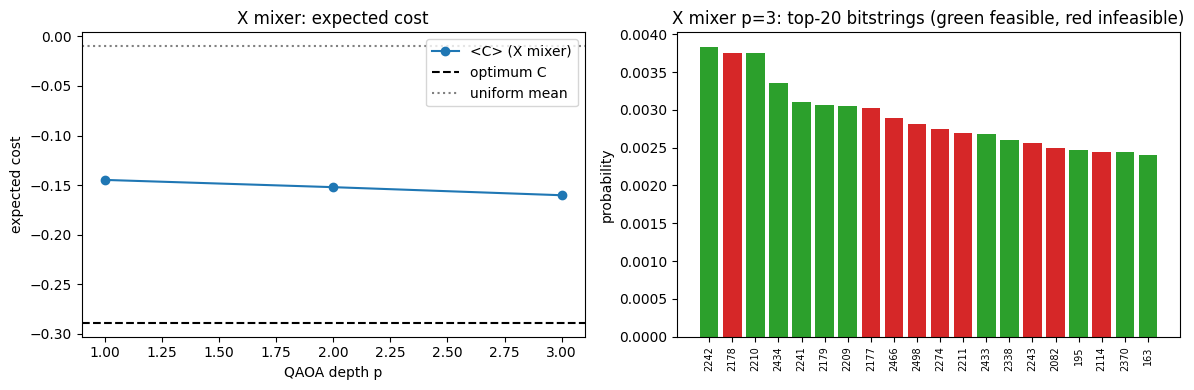

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tab_x["p"], tab_x["<C>"], "o-", label="<C> (X mixer)")
ax[0].axhline(C_min, color="k", ls="--", label="optimum C")
ax[0].axhline(C_mean_all, color="gray", ls=":", label="uniform mean")
ax[0].set_xlabel("QAOA depth p"); ax[0].set_ylabel("expected cost"); ax[0].legend(); ax[0].set_title("X mixer: expected cost")
r3 = runs_x[3]["psi"]
probs = np.abs(r3) ** 2
order = np.argsort(-probs)[:20]
cols = ["tab:green" if feas[b] else "tab:red" for b in order]
ax[1].bar(range(20), probs[order], color=cols)
ax[1].set_xticks(range(20)); ax[1].set_xticklabels([str(b) for b in order], rotation=90, fontsize=7)
ax[1].set_title("X mixer p=3: top-20 bitstrings (green feasible, red infeasible)")
ax[1].set_ylabel("probability")
plt.tight_layout(); plt.show()

In [9]:
rows_xy, runs_xy = [], {}
dicke = qpo.dicke_state(n, K, X)
for p in [1, 2, 3]:
    t0 = time.time()
    res = qpo.run_qaoa(C, n, p, mixer="xy", init=dicke, n_starts=6, seed=SEED + 10 + p)
    psi = qpo.qaoa_state(C, res["gammas"], res["betas"], n, "xy", dicke)
    st = qpo.measure_stats(psi, C, X, K, opt_b, shots=4096, seed=SEED + 10 + p)
    sb = st["best_sampled_feasible"]
    sel = qpo.bits_to_assets(sb, n) if sb is not None else []
    runs_xy[p] = dict(res, psi=psi, stats=st, sel=sel)
    rows_xy.append({
        "p": p, "<C>": res["expected_cost"],
        "AR (all)": qpo.approx_ratio(res["expected_cost"], C_mean_all, C_min),
        "AR (feas)": qpo.approx_ratio(res["expected_cost"], C_mean_feas, C_min),
        "P(opt)": st["p_opt"], "P(feasible)": st["p_feasible"],
        "shot feasible frac": st["shots_feasible_frac"],
        "best sampled feasible": ", ".join(qpo.TICKERS[i] for i in sel),
        "f(best sampled)": f_all[sb] if sb is not None else np.nan,
        "starts spread": max(res["all_run_costs"]) - min(res["all_run_costs"]),
        "sec": time.time() - t0,
    })
tab_xy = pd.DataFrame(rows_xy)
print("QAOA, ring XY mixer, Dicke |D^12_4> initial state (optimum f = %.6f):" % f_all[opt_b])
print(tab_xy.to_string(float_format=lambda v: f"{v:.5f}"))

QAOA, ring XY mixer, Dicke |D^12_4> initial state (optimum f = -0.288860):
   p      <C>  AR (all)  AR (feas)  P(opt)  P(feasible)  shot feasible frac best sampled feasible  f(best sampled)  starts spread     sec
0  1 -0.17452   0.59004    0.29635 0.00505      1.00000             1.00000    SPY, QQQ, GLD, XLK         -0.28886        0.00891 4.80795
1  2 -0.17631   0.59648    0.30741 0.00284      1.00000             1.00000    SPY, QQQ, GLD, XLK         -0.28886        0.03527 6.84241
2  3 -0.16176   0.54432    0.21788 0.00256      1.00000             1.00000    SPY, QQQ, GLD, XLK         -0.28886        0.01968 8.50749


In [10]:
# Is the QAOA distribution better than uniform guessing?  Conditional probability of the optimum
# given feasibility, compared with 1/495 for uniform over feasible subsets.
print(f"uniform over the 495 feasible subsets: P(opt) = {1/495:.5f};  uniform over all 4096: {1/4096:.6f}")
print()
rows = []
for mixer, runs in [("X", runs_x), ("XY", runs_xy)]:
    for p in [1, 2, 3]:
        pr = np.abs(runs[p]["psi"]) ** 2
        pr = pr / pr.sum()
        pf = pr[feas].sum()
        rows.append({"mixer": mixer, "p": p, "P(feasible)": pf, "P(opt)": pr[opt_b],
                     "P(opt | feasible)": pr[opt_b] / pf,
                     "x uniform-over-feasible": (pr[opt_b] / pf) * 495})
print(pd.DataFrame(rows).to_string(float_format=lambda v: f"{v:.5f}"))

# Sampling baseline: how often does uniform random sampling with 4096 shots hit the optimum?
rng_u = np.random.default_rng(SEED)
idx_feas = np.where(feas)[0]
hit_all, hit_feas = [], []
for rep in range(200):
    d_all = rng_u.integers(0, 2 ** n, size=4096)
    hit_all.append(bool(np.any(d_all == opt_b)))
    d_feas = idx_feas[rng_u.integers(0, len(idx_feas), size=4096)]
    hit_feas.append(bool(np.any(d_feas == opt_b)))
print("\nUniform random bitstrings, 4096 shots: optimum found in", f"{np.mean(hit_all):.3f}", "of 200 repetitions")
print("Uniform random feasible subsets, 4096 shots: optimum found in", f"{np.mean(hit_feas):.3f}", "of 200 repetitions")

uniform over the 495 feasible subsets: P(opt) = 0.00202;  uniform over all 4096: 0.000244

  mixer  p  P(feasible)  P(opt)  P(opt | feasible)  x uniform-over-feasible
0     X  1      0.33638 0.00184            0.00548                  2.71431
1     X  2      0.34002 0.00231            0.00679                  3.36045
2     X  3      0.34794 0.00307            0.00882                  4.36407
3    XY  1      1.00000 0.00505            0.00505                  2.50094
4    XY  2      1.00000 0.00284            0.00284                  1.40758
5    XY  3      1.00000 0.00256            0.00256                  1.26530

Uniform random bitstrings, 4096 shots: optimum found in 0.595 of 200 repetitions
Uniform random feasible subsets, 4096 shots: optimum found in 0.995 of 200 repetitions


In [11]:
# In-sample baselines (training window only), all with the same objective f(x) and K = 4
greedy = qpo.greedy_forward(mu, Sigma, q, K)
sharpe_in = mu / np.sqrt(np.diag(Sigma))
topk_sharpe = sorted(int(i) for i in np.argsort(-sharpe_in)[:K])
subsets = list(itertools.combinations(range(n), K))
f_subsets = np.array([qpo.subset_objective(s, mu, Sigma, q) for s in subsets])
print("Greedy forward selection:", [qpo.TICKERS[i] for i in greedy], f"f = {qpo.subset_objective(greedy, mu, Sigma, q):.6f}")
print("Top-4 by in-sample Sharpe:", [qpo.TICKERS[i] for i in topk_sharpe], f"f = {qpo.subset_objective(topk_sharpe, mu, Sigma, q):.6f}")
print("Random K-subsets (all 495), f distribution:",
      f"min {f_subsets.min():.6f}, 10% {np.quantile(f_subsets,0.1):.6f}, median {np.median(f_subsets):.6f}, "
      f"90% {np.quantile(f_subsets,0.9):.6f}, max {f_subsets.max():.6f}")
print("Rank of greedy among 495 subsets (1 = best):", int((f_subsets < qpo.subset_objective(greedy, mu, Sigma, q)).sum()) + 1)
print("Rank of top-Sharpe among 495 subsets (1 = best):", int((f_subsets < qpo.subset_objective(topk_sharpe, mu, Sigma, q)).sum()) + 1)

Greedy forward selection: ['SPY', 'QQQ', 'GLD', 'XLK'] f = -0.288860
Top-4 by in-sample Sharpe: ['SPY', 'QQQ', 'GLD', 'XLK'] f = -0.288860
Random K-subsets (all 495), f distribution: min -0.288860, 10% -0.210243, median -0.126968, 90% -0.045964, max 0.054528
Rank of greedy among 495 subsets (1 = best): 1
Rank of top-Sharpe among 495 subsets (1 = best): 1


In [12]:
# QAOA selections: best sampled feasible portfolio of each run
cands = {}
for p in [1, 2, 3]:
    cands[f"X p={p}"] = runs_x[p]["sel"]
    cands[f"XY p={p}"] = runs_xy[p]["sel"]
best_run = min(
    [("X", p, runs_x[p]["expected_cost"]) for p in [1, 2, 3]] + [("XY", p, runs_xy[p]["expected_cost"]) for p in [1, 2, 3]],
    key=lambda t: t[2])
qaoa_sel_name = f"{best_run[0]} p={best_run[1]}"
qaoa_sel = cands[qaoa_sel_name]
print("QAOA selection used for out-of-sample test = lowest <C> run:", qaoa_sel_name)
print("  assets:", [qpo.TICKERS[i] for i in qaoa_sel], " f(x) =", round(qpo.subset_objective(qaoa_sel, mu, Sigma, q), 6))
print("  feasible:", len(qaoa_sel) == K)

QAOA selection used for out-of-sample test = lowest <C> run: XY p=2
  assets: ['SPY', 'QQQ', 'GLD', 'XLK']  f(x) = -0.28886
  feasible: True


In [13]:
# Out-of-sample evaluation on the test window: equal weight, daily rebalanced
test_rows = {}
def add(name, assets):
    test_rows[name] = qpo.portfolio_metrics(assets, te)

add(f"QAOA ({qaoa_sel_name})", qaoa_sel)
add("Brute-force optimum", qpo.bits_to_assets(opt_b, n))
add("Greedy forward", greedy)
add("Top-4 in-sample Sharpe", topk_sharpe)
rand_metrics = [qpo.portfolio_metrics(s, te) for s in subsets]
rand_med = {k: float(np.median([m[k] for m in rand_metrics])) for k in ["ann_return", "ann_vol", "sharpe", "max_drawdown"]}
test_rows["Random K-subset (median of 495)"] = dict(rand_med, wealth=None)
add("Equal weight all 12", list(range(n)))

tab_test = pd.DataFrame({k: {m: v[m] for m in ["ann_return", "ann_vol", "sharpe", "max_drawdown"]} for k, v in test_rows.items()}).T
tab_test.columns = ["ann return", "ann vol", "Sharpe", "max drawdown"]
print("Out-of-sample (2023-01-03 to 2026-11-19), equal weight of the chosen subset:")
print(tab_test.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nIn-sample f(x) of each selection (training window):")
for nm, s in [("QAOA", qaoa_sel), ("Brute-force", qpo.bits_to_assets(opt_b, n)), ("Greedy", greedy), ("Top-4 Sharpe", topk_sharpe)]:
    print(f"  {nm:12s} {qpo.subset_objective(s, mu, Sigma, q):.6f}")

Out-of-sample (2023-01-03 to 2026-11-19), equal weight of the chosen subset:
                                 ann return  ann vol  Sharpe  max drawdown
QAOA (XY p=2)                        0.2329   0.1642  1.4184       -0.1689
Brute-force optimum                  0.2329   0.1642  1.4184       -0.1689
Greedy forward                       0.2329   0.1642  1.4184       -0.1689
Top-4 in-sample Sharpe               0.2329   0.1642  1.4184       -0.1689
Random K-subset (median of 495)      0.1430   0.1271  1.1222       -0.1366
Equal weight all 12                  0.1428   0.1140  1.2525       -0.1288

In-sample f(x) of each selection (training window):
  QAOA         -0.288860
  Brute-force  -0.288860
  Greedy       -0.288860
  Top-4 Sharpe -0.288860


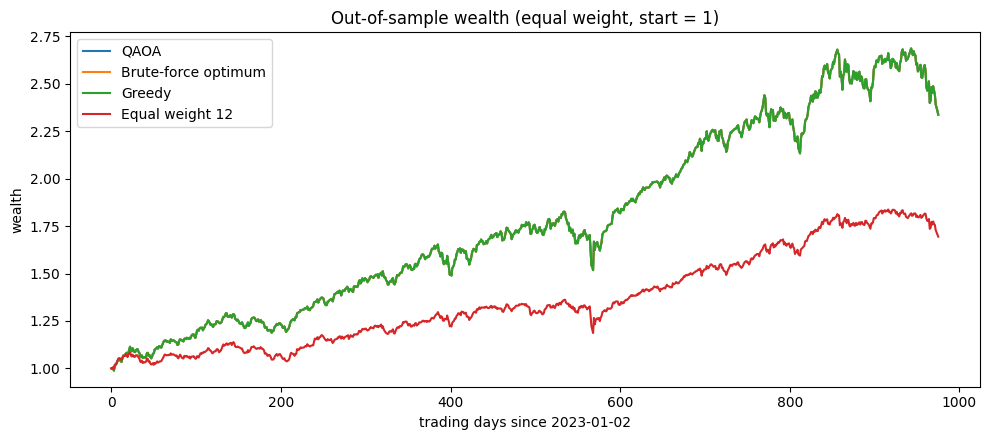

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for nm, s in [("QAOA", qaoa_sel), ("Brute-force optimum", qpo.bits_to_assets(opt_b, n)),
              ("Greedy", greedy), ("Equal weight 12", list(range(n)))]:
    w = qpo.portfolio_metrics(s, te)["wealth"]
    ax.plot(np.arange(len(w)), w, label=nm)
ax.set_xlabel("trading days since 2023-01-02")
ax.set_title("Out-of-sample wealth (equal weight, start = 1)")
ax.set_ylabel("wealth"); ax.legend(); plt.tight_layout(); plt.show()

## Results

Measured in the run above (seeds fixed; K = 4 of n = 12, q = 0.5).

**Data and QUBO checks**

- 2,989 daily rows, 2015-01-02 to 2026-11-19, no missing values. Training returns: 2,013 (2015-01-05 to 2022-12-30). Test returns: 975 (2023-01-03 to 2026-11-19). Ledoit-Wolf shrinkage intensity 0.0125.
- Penalty A = 0.008 (first value in the doubling sequence whose global minimum is feasible). The margin is thin: the best infeasible C is only 0.00048 above the best feasible C.
- Max |QUBO - direct penalised objective| = 1.3e-15 and max |Ising - QUBO| = 1.3e-15 over all 4096 bitstrings.
- Qiskit cross-check (p = 2, X mixer): |<psi_numpy|psi_qiskit>| = 1.000000000000 and <C> = 0.005317181209 from both the numpy state and `SparsePauliOp` on the Ising form.

**Brute force (exact, K = 4)**

- Optimum: SPY, QQQ, GLD, XLK with f(x) = -0.288860. Runner-up: QQQ, GLD, DBC, XLK with f = -0.284882.
- Over the 495 feasible subsets, the median f is -0.126968 (10th to 90th percentile: -0.210243 to -0.045964).

**QAOA by statevector (COBYLA, 6 starts per p, 4096 shots)**

| mixer | p | <C> | AR (all 4096) | AR (feasible) | P(optimum) | P(feasible) |
|---|---|---|---|---|---|---|
| X | 1 | -0.14474 | 0.483 | 0.113 | 0.00184 | 0.336 |
| X | 2 | -0.15206 | 0.510 | 0.158 | 0.00231 | 0.340 |
| X | 3 | -0.16020 | 0.539 | 0.208 | 0.00307 | 0.348 |
| XY, Dicke init | 1 | -0.17452 | 0.590 | 0.296 | 0.00505 | 1.000 |
| XY, Dicke init | 2 | -0.17631 | 0.596 | 0.307 | 0.00284 | 1.000 |
| XY, Dicke init | 3 | -0.16176 | 0.544 | 0.218 | 0.00256 | 1.000 |

- QAOA did not reach the optimum in expectation (optimum C = -0.288860). The best expected cost was -0.17631 (XY, p = 2).
- Every configuration's best sampled feasible portfolio was the optimum. This does not show quantum advantage. Uniform random feasible subsets with 4096 shots also hit the optimum in 0.995 of 200 repetitions (uniform over all bitstrings: 0.595).
- P(optimum | feasible) divided by 1/495 is 4.4 for X p = 3, 2.5 for XY p = 1, 1.4 for XY p = 2 and 1.3 for XY p = 3.
- The XY mixer keeps P(feasible) = 1 exactly. The X mixer puts about 65% of probability on infeasible bitstrings.
- Results are not monotone in p (XY p = 3 is worse than p = 2, and the multi-start spread is 0.017 to 0.035), so the optimiser is finding local minima and the depth results are not converged.

**Baselines (training window)**

- Greedy forward selection and top-4 by in-sample Sharpe both return SPY, QQQ, GLD, XLK, the brute-force optimum (rank 1 of 495).

**Out-of-sample (2023-01-03 to 2026-11-19, equal weight, daily rebalanced, rf = 0)**

| selection | ann. return | ann. vol | Sharpe | max drawdown |
|---|---|---|---|---|
| QAOA (XY p = 2 best sample) = optimum = greedy = top-4 Sharpe (SPY, QQQ, GLD, XLK) | 23.29% | 16.42% | 1.418 | -16.89% |
| Random 4-subset, median of 495 | 14.30% | 12.71% | 1.122 | -13.66% |
| Equal weight, all 12 | 14.28% | 11.40% | 1.253 | -12.88% |

- QAOA selected the same subset as the classical methods, so the out-of-sample row says nothing about QAOA itself. Greedy did not lose to QAOA, and QAOA did not beat greedy.
- The chosen subset is only as good as the in-sample mu and Sigma. The 2015-2022 means favour XLK and QQQ, and one 2023-2026 test path is a single realisation, not a robustness test.
- No transaction costs are modelled. Returns are arithmetic and annualised by 252 days.

## Conclusions
1. **The problem formulation is correct and verified.** The 12-asset, choose-4 selection (495 feasible portfolios out of 4,096 bitstrings) was written as a QUBO and an Ising Hamiltonian; the cost function matches the direct penalised objective to 1e-15 on all bitstrings, the global minimum is a feasible portfolio (SPY, QQQ, GLD, XLK), and a Qiskit circuit gives the same state (overlap 1.000000) and the same expectation value (0.005317) as the NumPy simulator. The penalty margin is thin, though: the best infeasible bitstring is only 0.00048 worse than the best feasible one.
2. **QAOA at depth 1 to 3 concentrates probability only a little around the optimum.** With the standard X mixer the probability of measuring the optimal portfolio is 0.18% to 0.31%, against 0.20% for a uniformly random feasible portfolio and 0.024% for a random bitstring, and only about a third of the sampled bitstrings are feasible (0.34 to 0.35). With the ring XY mixer started from the 4-asset Dicke state, every sample is feasible by construction, but the probability of the optimum is 0.26% to 0.51%, only 1.3 to 2.5 times the random-feasible baseline. The best expected-cost approximation ratio over the feasible subsets is 0.31.
3. **Sampling finds the optimum, but that is not evidence of advantage.** Every QAOA configuration produced the optimal portfolio among its 4,096 samples, but picking random feasible portfolios 4,096 times also finds it in 99.5% of repetitions, because there are only 495 candidates. Greedy forward selection and the top-4 by in-sample Sharpe also return exactly the same portfolio, so QAOA matched the classical methods and did not beat them.
4. **Depth did not help monotonically.** The ring-mixer expectation is better at p = 2 (-0.176) than at p = 3 (-0.162), which means the classical optimiser (COBYLA with 6 starts) did not converge at depth 3; more starts or a better optimiser would be needed before drawing conclusions about depth.
5. **The out-of-sample test says nothing specific about QAOA.** Because every method picked the same portfolio, its 2023 to 2026 result (annual return 23.3%, volatility 16.4%, Sharpe 1.42, maximum drawdown -16.9%, against Sharpe 1.12 for the median random subset and 1.25 for equal weight of all 12) measures the selection rule (in-sample mean-variance score), not the quantum algorithm. The result also depends on the training window: the subset is only as good as the in-sample expected returns.
6. **Limits.** Twelve qubits is easy to simulate and to solve by brute force, there is no hardware noise, one train/test split, no transaction costs, and the last price bar (2026-11-19) is included as returned by the data provider.

**Takeaway for the interview:** the contribution of this project is the formulation (QUBO, Ising, constraint handling with a penalty or a constraint-preserving mixer) and an honest benchmark: at sizes that can be simulated, QAOA is not better than brute force, greedy search or even random sampling, and any claim of quantum advantage would need a problem too large for classical methods.

## Conclusions
1. **The problem formulation is correct and verified.** The 12-asset, choose-4 selection (495 feasible portfolios out of 4,096 bitstrings) was written as a QUBO and an Ising Hamiltonian; the cost function matches the direct penalised objective to 1e-15 on all bitstrings, the global minimum is a feasible portfolio (SPY, QQQ, GLD, XLK), and a Qiskit circuit gives the same state (overlap 1.000000) and the same expectation value (0.005317) as the NumPy simulator. The penalty margin is thin, though: the best infeasible bitstring is only 0.00048 worse than the best feasible one.
2. **QAOA at depth 1 to 3 concentrates probability only a little around the optimum.** With the standard X mixer the probability of measuring the optimal portfolio is 0.18% to 0.31%, against 0.20% for a uniformly random feasible portfolio and 0.024% for a random bitstring, and only about a third of the sampled bitstrings are feasible (0.34 to 0.35). With the ring XY mixer started from the 4-asset Dicke state, every sample is feasible by construction, but the probability of the optimum is 0.26% to 0.51%, only 1.3 to 2.5 times the random-feasible baseline. The best expected-cost approximation ratio over the feasible subsets is 0.31.
3. **Sampling finds the optimum, but that is not evidence of advantage.** Every QAOA configuration produced the optimal portfolio among its 4,096 samples, but picking random feasible portfolios 4,096 times also finds it in 99.5% of repetitions, because there are only 495 candidates. Greedy forward selection and the top-4 by in-sample Sharpe also return exactly the same portfolio, so QAOA matched the classical methods and did not beat them.
4. **Depth did not help monotonically.** The ring-mixer expectation is better at p = 2 (-0.176) than at p = 3 (-0.162), which means the classical optimiser (COBYLA with 6 starts) did not converge at depth 3; more starts or a better optimiser would be needed before drawing conclusions about depth.
5. **The out-of-sample test says nothing specific about QAOA.** Because every method picked the same portfolio, its 2023 to 2026 result (annual return 23.3%, volatility 16.4%, Sharpe 1.42, maximum drawdown -16.9%, against Sharpe 1.12 for the median random subset and 1.25 for equal weight of all 12) measures the selection rule (in-sample mean-variance score), not the quantum algorithm. The result also depends on the training window: the subset is only as good as the in-sample expected returns.
6. **Limits.** Twelve qubits is easy to simulate and to solve by brute force, there is no hardware noise, one train/test split, no transaction costs, and the last price bar (2026-11-19) is included as returned by the data provider.

**Takeaway for the interview:** the contribution of this project is the formulation (QUBO, Ising, constraint handling with a penalty or a constraint-preserving mixer) and an honest benchmark: at sizes that can be simulated, QAOA is not better than brute force, greedy search or even random sampling, and any claim of quantum advantage would need a problem too large for classical methods.